# 10a — Demonstração: previsões da CNN-1D para os vídeos da apresentação

**Trabalho final — Tópicos Especiais em ESSC II (IA aplicada a Séries Temporais)**

Este notebook prepara a demonstração prática do trabalho. Ele não treina nada: usa as **CNN-1D já treinadas no notebook 09** (sinal bruto, semente 0), uma por rodada, e calcula para cada vídeo:

1. a **previsão ao vivo**: as probabilidades das 20 palavras depois de observar 1, 2, …, 32 instantes do sinal (a classificação antecipada do notebook 05);
2. o **CAM** da palavra prevista, que mostra em que instantes está a evidência (notebook 09, parte C).

**Honestidade da demonstração:** cada vídeo é classificado pelo modelo da rodada em que o seu sinalizante era **teste**, isto é, por uma rede que **nunca viu aquela pessoa**. A entrada é exatamente a série usada nas avaliações do artigo (`minds_st.npz`).

No fim, o notebook escolhe os vídeos da demonstração: **um acerto por palavra** (20 vídeos, variando os sinalizantes) e **alguns erros**, e grava tudo em `resultados/10_demo/previsoes_demo.npz`. O notebook **10b** usa esse arquivo para montar os vídeos com o esqueleto do MediaPipe.

Roda em ~2 minutos (GPU ou CPU), no ambiente `venv_tf`.

## 1. Configuração

In [1]:
import os
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.get_logger().setLevel("ERROR")
BASE = Path.cwd().parent if (Path.cwd().parent / "dados").exists() else Path.cwd()
DADOS, RES, FIG = BASE / "dados", BASE / "resultados", BASE / "figuras"
PESOS, SAIDA = RES / "09_pesos", RES / "10_demo"
SAIDA.mkdir(parents=True, exist_ok=True)
NOMES = {"america": "américa", "maca": "maçã"}
N_ERROS = 3                      # quantos exemplos de erro entram na demonstração
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

d = np.load(DADOS / "minds_st.npz", allow_pickle=False)
X, y = d["X"].astype(np.float32), d["y"]
classes = d["classes"].astype(str)
sinalizante, grupo, VAL = d["sinalizante"], d["grupo"], d["validacao"]
arquivo, t0, t1, espelhado = d["arquivo"].astype(str), d["t0"], d["t1"], d["espelhado"]
N, T, F = X.shape
K = len(classes)
faltando = [k for k in range(4) if not (PESOS / f"cnn1d_bruto_r{k}.weights.h5").exists()]
assert not faltando, f"Faltam os pesos das rodadas {faltando}: rode o notebook 09 antes."
print(f"{N} vídeos | T={T} | F={F} | {K} palavras | TensorFlow {tf.__version__}")

I0000 00:00:1795797230.850396     462 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795797242.131423     462 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


1158 vídeos | T=32 | F=321 | 20 palavras | TensorFlow 2.21.0


## 2. O modelo

Mesma arquitetura da CNN-1D dos notebooks 03 e 09: 3 convoluções (64, 128 e 128 filtros), *batch norm*, ReLU, média global (GAP) e saída com 20 classes. Aqui a entrada aceita **qualquer comprimento** (`None` instantes), para dar a previsão com só parte do sinal; os pesos não dependem do comprimento. O ruído gaussiano e o *dropout* só agem no treino.

In [2]:
def particao(rodada):
    te = np.where(grupo == rodada)[0]
    va = np.where(np.isin(sinalizante, VAL[rodada]))[0]
    tr = np.setdiff1d(np.arange(N), np.concatenate([te, va]))
    return tr, va, te

def cnn1d(F_in=F):
    x_in = keras.Input(shape=(None, F_in))
    h = layers.GaussianNoise(0.1)(x_in)
    for filtros, k in [(64, 5), (128, 5), (128, 3)]:
        h = layers.Activation("relu")(layers.BatchNormalization()(layers.Conv1D(filtros, k, padding="same")(h)))
    h = layers.GlobalAveragePooling1D(name="gap")(h)
    return keras.Model(x_in, layers.Dense(K, activation="softmax", name="saida")(layers.Dropout(0.3)(h)), name="CNN-1D")

def carregar(rodada):
    keras.backend.clear_session()
    m = cnn1d()
    m.load_weights(PESOS / f"cnn1d_bruto_r{rodada}.weights.h5")
    ult = [l for l in m.layers if isinstance(l, layers.Activation)][-1].output
    return m, keras.Model(m.input, ult)

## 3. Previsão instante a instante e CAM

Para cada rodada: padroniza com a média e o desvio **do treino daquela rodada** (como em todo o trabalho), e para cada prefixo de h = 1, …, 32 instantes guarda as probabilidades das 20 palavras. O CAM é calculado com a série completa, para a palavra prevista.

In [3]:
prob = np.zeros((N, T, K), np.float32)           # prob[v, h-1] = probabilidades depois de h instantes
cam = np.zeros((N, T), np.float32)
rodada_de = np.full(N, -1)
for k in range(4):
    tr, va, te = particao(k)
    mu, sd = X[tr].reshape(-1, F).mean(0), X[tr].reshape(-1, F).std(0) + 1e-6
    Z = ((X[te] - mu) / sd).astype(np.float32)
    m, sub = carregar(k)
    for h in range(1, T + 1):
        prob[te, h - 1] = m(Z[:, :h], training=False).numpy()
    A = sub(Z, training=False).numpy()                                   # (n, T, 128)
    W = m.get_layer("saida").get_weights()[0]                            # (128, K)
    c = np.einsum("ntk,kn->nt", A, W[:, prob[te, -1].argmax(1)])
    c = np.maximum(c, 0)
    cam[te] = c / (c.max(1, keepdims=True) + 1e-9)
    rodada_de[te] = k
    print(f"rodada {k}: {len(te)} vídeos de teste (sinalizantes {sorted(set(sinalizante[te]))}) | "
          f"acurácia com o sinal inteiro {np.mean(prob[te, -1].argmax(1) == y[te]):.3f}")

pred = prob[:, -1].argmax(1)
conf = prob[:, -1].max(1)
acerto = pred == y
print(f"\nacurácia geral: {acerto.mean():.3f} (notebook 09: 0,923)")

rodada 0: 275 vídeos de teste (sinalizantes [np.int64(1), np.int64(5), np.int64(9)]) | acurácia com o sinal inteiro 0.935


rodada 1: 300 vídeos de teste (sinalizantes [np.int64(2), np.int64(6), np.int64(10)]) | acurácia com o sinal inteiro 0.933


rodada 2: 288 vídeos de teste (sinalizantes [np.int64(3), np.int64(7), np.int64(11)]) | acurácia com o sinal inteiro 0.906


rodada 3: 295 vídeos de teste (sinalizantes [np.int64(4), np.int64(8), np.int64(12)]) | acurácia com o sinal inteiro 0.919

acurácia geral: 0.923 (notebook 09: 0,923)


### Quão cedo a previsão "trava" na resposta final?

Para cada vídeo, o **instante de decisão** é o primeiro instante a partir do qual a palavra prevista não muda mais até o fim. A curva abaixo é a acurácia ao longo do sinal: é a curva do horizonte (notebook 05, estratégia "sem adaptação") instante a instante.

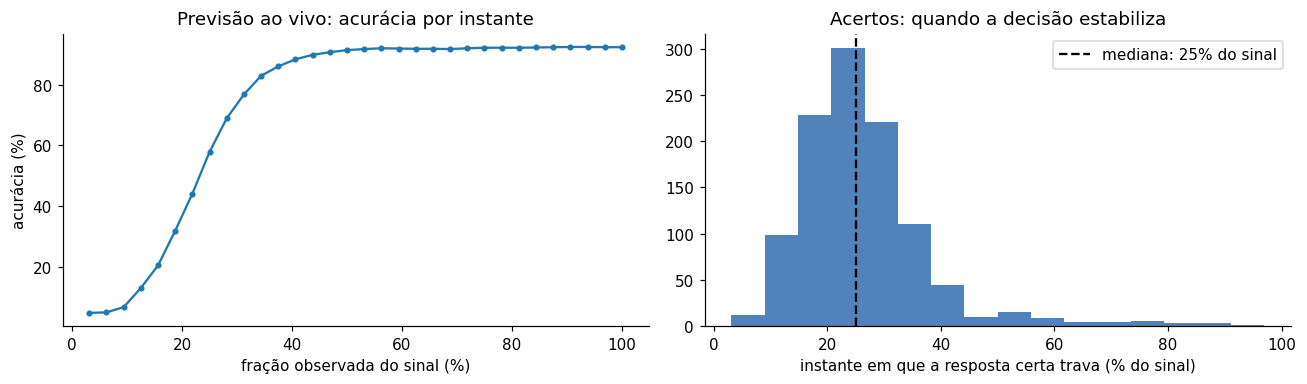

In [4]:
def instante_decisao(p):
    final = p[-1].argmax()
    mudou = np.where(p.argmax(1) != final)[0]
    return (mudou[-1] + 2) if len(mudou) else 1           # 1..32

decisao = np.array([instante_decisao(prob[v]) for v in range(N)])
acc_h = (prob.argmax(2) == y[:, None]).mean(0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(np.arange(1, T + 1) / T * 100, 100 * acc_h, "o-", ms=3)
ax[0].set_xlabel("fração observada do sinal (%)"); ax[0].set_ylabel("acurácia (%)")
ax[0].set_title("Previsão ao vivo: acurácia por instante")
ax[1].hist(decisao[acerto] / T * 100, bins=16, color="#2563A8", alpha=.8)
ax[1].axvline(np.median(decisao[acerto]) / T * 100, color="k", ls="--",
              label=f"mediana: {np.median(decisao[acerto]) / T * 100:.0f}% do sinal")
ax[1].set_xlabel("instante em que a resposta certa trava (% do sinal)"); ax[1].legend()
ax[1].set_title("Acertos: quando a decisão estabiliza")
plt.tight_layout(); plt.savefig(FIG / "10_previsao_ao_vivo.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Escolha dos vídeos da demonstração

- **Acertos (20 vídeos, um por palavra):** entre os vídeos acertados com confiança ≥ 80% e decisão estável antes do fim do sinal, escolhe o de maior confiança, preferindo sinalizantes ainda pouco usados, para mostrar pessoas diferentes.
- **Erros:** os erros mais confiantes (o modelo errou "com certeza"), no máximo um por par de palavras confundidas, e com sinalizantes diferentes.

In [5]:
usados = {}
escolhidos = []
for c in np.argsort([-(y == c).sum() for c in range(K)]):              # qualquer ordem serve
    cand = np.where((y == c) & acerto)[0]
    bons = cand[(conf[cand] >= 0.8) & (decisao[cand] <= T - 2)]
    if len(bons) == 0:
        bons = cand
    # menor uso do sinalizante primeiro, depois maior confiança
    v = sorted(bons, key=lambda i: (usados.get(sinalizante[i], 0), -conf[i]))[0]
    usados[sinalizante[v]] = usados.get(sinalizante[v], 0) + 1
    escolhidos.append(int(v))
escolhidos = sorted(escolhidos, key=lambda v: classes[y[v]])

erros, pares, sinais_err = [], set(), set()
for v in np.where(~acerto)[0][np.argsort(-conf[~acerto])]:
    par = tuple(sorted((y[v], pred[v])))
    if par in pares or sinalizante[v] in sinais_err:
        continue
    erros.append(int(v)); pares.add(par); sinais_err.add(sinalizante[v])
    if len(erros) == N_ERROS:
        break

demo = escolhidos + erros
tabela = pd.DataFrame({
    "tipo": ["acerto"] * len(escolhidos) + ["erro"] * len(erros),
    "palavra": [NOMES.get(c, c) for c in classes[y[demo]]], "previsto": [NOMES.get(c, c) for c in classes[pred[demo]]],
    "confiança (%)": (100 * conf[demo]).round(1), "sinalizante": sinalizante[demo],
    "rodada (modelo)": rodada_de[demo], "decide em (% do sinal)": (100 * decisao[demo] / T).round(0),
    "arquivo": [a.split("/")[-1] for a in arquivo[demo]]})
display(tabela)
print("sinalizantes nos acertos:", dict(sorted(usados.items())))

,tipo,palavra,previsto,confiança (%),sinalizante,rodada (modelo),decide em (% do sinal),arquivo
0,acerto,acontecer,acontecer,100.000000,9,0,12.0,01AcontecerSinalizador09-2.mp4
1,acerto,aluno,aluno,100.000000,2,1,9.0,02AlunoSinalizador02-5.mp4
2,acerto,amarelo,amarelo,100.000000,1,0,19.0,03AmareloSinalizador01-4.mp4
3,acerto,américa,américa,100.000000,9,0,16.0,04AmericaSinalizador09-1.mp4
4,acerto,aproveitar,aproveitar,99.900002,1,0,31.0,05AproveitarSinalizador01-2.mp4
5,acerto,bala,bala,100.000000,5,0,25.0,06BalaSinalizador05-4.mp4
6,acerto,banco,banco,100.000000,12,3,22.0,07BancoSinalizador12-5.mp4
7,acerto,banheiro,banheiro,99.699997,10,1,25.0,08BanheiroSinalizador10-3.mp4
8,acerto,barulho,barulho,100.000000,2,1,19.0,09BarulhoSinalizador02-1.mp4
9,acerto,cinco,cinco,100.000000,11,2,16.0,10CincoSinalizador11-4.mp4


sinalizantes nos acertos: {np.int64(1): 2, np.int64(2): 2, np.int64(3): 1, np.int64(4): 2, np.int64(5): 2, np.int64(6): 2, np.int64(7): 1, np.int64(8): 1, np.int64(9): 2, np.int64(10): 1, np.int64(11): 2, np.int64(12): 2}


In [6]:
np.savez_compressed(SAIDA / "previsoes_demo.npz",
    indice=np.array(demo), tipo=np.array(tabela.tipo, dtype=str), arquivo=arquivo[demo], y=y[demo], pred=pred[demo],
    prob=prob[demo], cam=cam[demo], t0=t0[demo], t1=t1[demo], espelhado=espelhado[demo],
    sinalizante=sinalizante[demo], rodada=rodada_de[demo], decisao=decisao[demo], classes=classes)
tabela.to_csv(SAIDA / "videos_demo.csv", index=False)
print("gravado em", SAIDA / "previsoes_demo.npz")

gravado em /mnt/d/ProjetoMestrado/trabalho_series_temporais/resultados/10_demo/previsoes_demo.npz


## 5. Próximo passo

Rode o notebook **10b_demo_video** no ambiente com o MediaPipe (`venv_mp`). Ele tira cada vídeo do ZIP do MINDS, desenha o esqueleto quadro a quadro e monta o painel com a previsão ao vivo, gravando um MP4 por vídeo e um vídeo-resumo em `resultados/10_demo/`.